# Compare daily forecasts at a location

Choose a latitude/longitude. The reader finds the nearest original pixel by spherical distance, then reads that same pixel from each daily file. This example requires all 19 files. Locations more than 25 km from the grid are rejected.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'manifest.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'manifest.json').exists(), 'Run from the package root or notebooks folder.'
sys.path.insert(0, str(ROOT / 'examples'))
import outlook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
LATITUDE, LONGITUDE = 44.8, -120.4
series = outlook.point_series(LATITUDE, LONGITUDE)
assert len(series) == 19
print('Selected native pixel:', series.attrs)
series

Selected native pixel: {'row': 1308, 'col': 1943, 'latitude': 44.80158615112305, 'longitude': -120.40054321289062, 'distance_km': 0.18122748748144957}


,issue,valid_start,valid_end,outlook_index,category
0,2026-07-03 03:00:00+00:00,2026-07-03 12:00:00+00:00,2026-07-04 12:00:00+00:00,0.663247,3
1,2026-07-04 03:00:00+00:00,2026-07-04 12:00:00+00:00,2026-07-05 12:00:00+00:00,0.813336,6
2,2026-07-05 03:00:00+00:00,2026-07-05 12:00:00+00:00,2026-07-06 12:00:00+00:00,0.769015,5
3,2026-07-06 03:00:00+00:00,2026-07-06 12:00:00+00:00,2026-07-07 12:00:00+00:00,0.697494,3
4,2026-07-07 03:00:00+00:00,2026-07-07 12:00:00+00:00,2026-07-08 12:00:00+00:00,0.588113,2
5,2026-07-08 03:00:00+00:00,2026-07-08 12:00:00+00:00,2026-07-09 12:00:00+00:00,0.868410,6
6,2026-07-09 03:00:00+00:00,2026-07-09 12:00:00+00:00,2026-07-10 12:00:00+00:00,0.837559,6
7,2026-07-10 03:00:00+00:00,2026-07-10 12:00:00+00:00,2026-07-11 12:00:00+00:00,0.874130,6
8,2026-07-11 03:00:00+00:00,2026-07-11 12:00:00+00:00,2026-07-12 12:00:00+00:00,0.695701,3
9,2026-07-12 03:00:00+00:00,2026-07-12 12:00:00+00:00,2026-07-13 12:00:00+00:00,0.701749,3


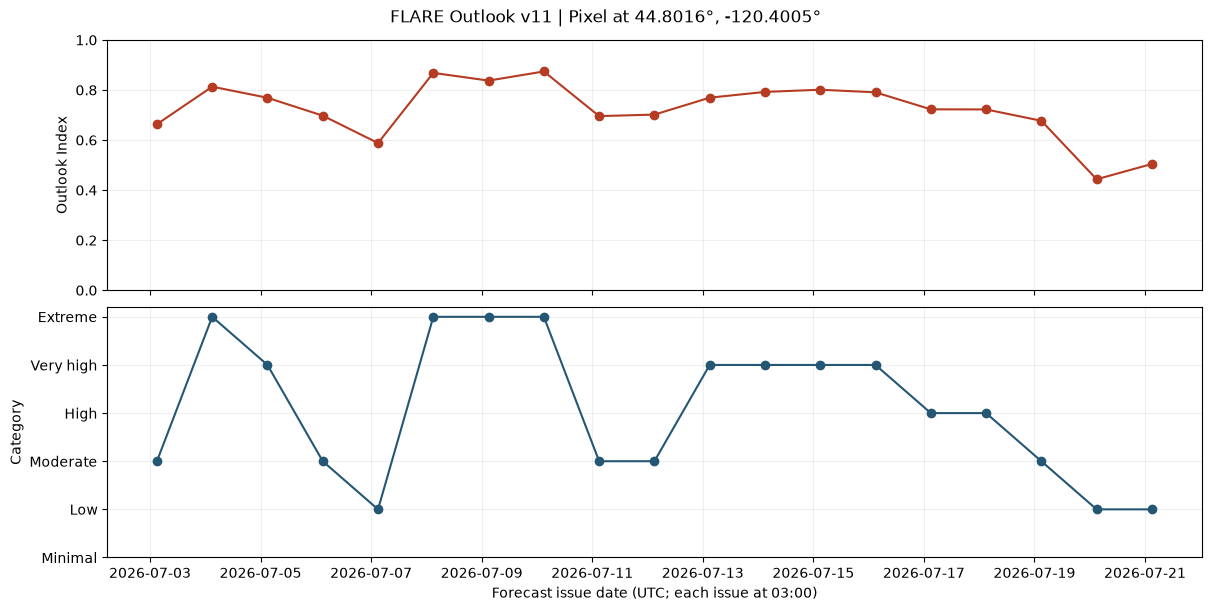

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout='constrained')
for ax, key in zip(axes, ['outlook_index', 'category']):
    values = series[key].where(series[key] != 0) if key != 'outlook_index' else series[key]
    ax.plot(series.issue, values, marker='o', color='#b53b22' if key == 'outlook_index' else '#245774')
    ax.set_ylabel(key.replace('_', ' ').title())
    ax.grid(alpha=.2)
axes[0].set_ylim(0, 1)
axes[1].set_yticks(range(1, 7), outlook.CATEGORY_LABELS[1:])
axes[1].set_xlabel('Forecast issue date (UTC; each issue at 03:00)')
fig.suptitle(f'FLARE Outlook v11 | Pixel at {series.attrs["latitude"]:.4f}°, {series.attrs["longitude"]:.4f}°')
plt.show()

Class 0 is displayed as a gap, not as a low category. The table retains the original 0 codes and includes the valid interval for each daily forecast.